In [1]:
# load data
import pandas as pd

df = pd.read_csv('genshin_characters_v1.csv')
df

,character_name,star_rarity,region,vision,arkhe,weapon_type,release_date,model,constellation,birthday,...,atk_1_20,def_1_20,ascension_special_stat,special_0,special_1,special_2,special_3,special_4,special_5,special_6
0,Albedo,5,Mondstadt,Geo,NaN,Sword,2020-12-23,Medium Male,Princeps Cretaceus,13-Sep,...,20,68,Geo DMG Bonus,0.00%,0.00%,7.20%,14.40%,14.40%,21.60%,28.80%
1,Alhaitham,5,Sumeru,Dendro,NaN,Sword,2023-01-18,Tall Male,Vultur Volans,11-Feb,...,24,60,Dendro DMG Bonus,0.00%,0.00%,7.20%,14.40%,14.40%,21.60%,28.80%
2,Aloy,5,NaN,Cryo,NaN,Bow,2021-09-01,Medium Female,Nora Fortis,04-Apr,...,18,53,Cryo DMG Bonus,0.00%,0.00%,7.20%,14.40%,14.40%,21.60%,28.80%
3,Amber,4,Mondstadt,Pyro,NaN,Bow,2020-09-28,Medium Female,Lepus,10-Aug,...,19,50,ATK,0.00%,0.00%,6.00%,12.00%,12.00%,18.00%,24.00%
4,Arataki Itto,5,Inazuma,Geo,NaN,Claymore,2021-12-14,Tall Male,Taurus Iracundus,01-Jun,...,18,75,CRIT Rate,0.00%,0.00%,4.80%,9.60%,9.60%,14.40%,19.20%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,Yaoyao,4,Liyue,Dendro,NaN,Polearm,2023-01-18,Short Female,Osmanthus,06-Mar,...,17,62,HP,0.00%,0.00%,6.00%,12.00%,12.00%,18.00%,24.00%
90,Yelan,5,Liyue,Hydro,NaN,Bow,2022-05-31,Tall Female,Umbrabilis Orchis,20-Apr,...,19,43,CRIT Rate,0.00%,0.00%,4.80%,9.60%,9.60%,14.40%,19.20%
91,Yoimiya,5,Inazuma,Pyro,NaN,Bow,2021-08-10,Medium Female,Carassius Auratus,21-Jun,...,25,48,CRIT Rate,0.00%,0.00%,4.80%,9.60%,9.60%,14.40%,19.20%
92,Yun Jin,4,Liyue,Geo,NaN,Polearm,2022-01-05,Medium Female,Opera Grandis,21-May,...,16,62,Energy Recharge,0.00%,0.00%,6.70%,13.30%,13.30%,20.00%,26.70%


In [4]:
# EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()} \n')

print(f'Cek data duplicate \n {df.duplicated().sum()}')

Cek 5 data teratas 
    character_name  star_rarity    region   vision   arkhe weapon_type  \
11      Charlotte            4  Fontaine     Cryo  Pneuma    Catalyst   
12      Chevreuse            4  Fontaine     Pyro   Ousia     Polearm   
15       Clorinde            5  Fontaine  Electro   Ousia       Sword   
22         Emilie            5  Fontaine   Dendro  Pneuma     Polearm   
26       Freminet            4  Fontaine     Cryo  Pneuma    Claymore   

   release_date          model        constellation birthday  ... atk_1_20  \
11   2023-11-08  Medium Female      Hualina Veritas   10-Apr  ...       14   
12   2024-01-09  Medium Female  Sclopetum Ensiferum   10-Jan  ...       16   
15   2024-06-05    Tall Female             Rapperia   20-Sep  ...       26   
22   2024-08-06  Medium Female       Pomum de Ambra   22-Sep  ...       26   
26   2023-09-05    Medium Male            Automaton   24-Sep  ...       21   

   def_1_20 ascension_special_stat special_0 special_1 special_2 specia

In [ ]:
# handle missing values
df.dropna(inplace=True)

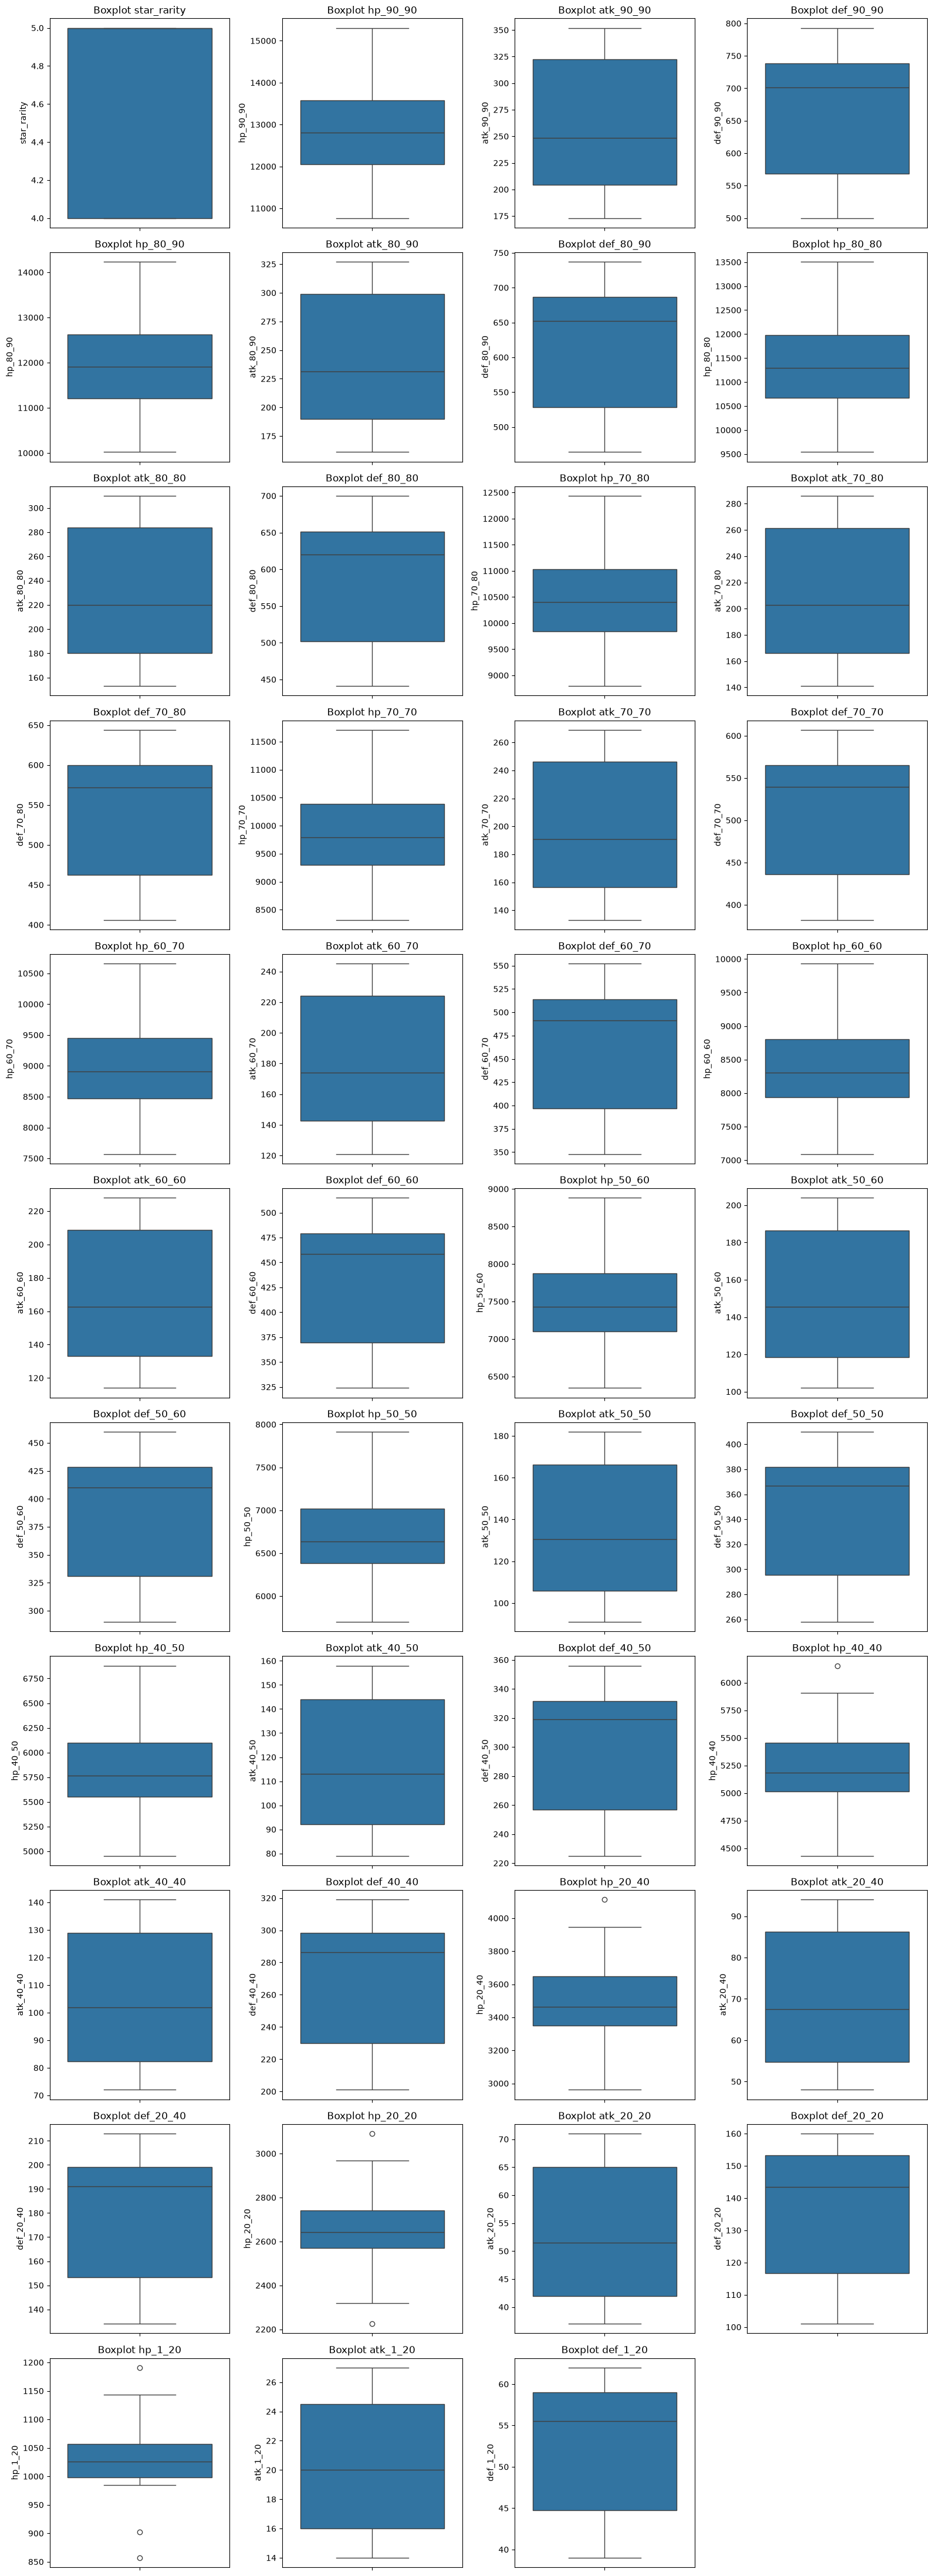

In [5]:
# outlier
import math
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = df.select_dtypes(include='number').columns

## Outlier
n_cols = 4  # jumlah plot per baris, silakan diubah
n_rows = math.ceil(len(numerical_columns) / n_cols)

plt.figure(figsize=(4 * n_cols, 4 * n_rows))

for i, column in enumerate(numerical_columns):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(y=df[column])
    plt.title(f'Boxplot {column}')

plt.tight_layout()
plt.show()

In [7]:
# handle outlier
numerical_columns = df.select_dtypes(include='number').columns

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
)

outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_mask.sum(),
    'Percentage': outlier_mask.mean() * 100
})

outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
)

,Outlier Count,Percentage
hp_1_20,3,25.000000
hp_20_20,2,16.666667
hp_40_40,1,8.333333
hp_20_40,1,8.333333
hp_80_90,0,0.000000
atk_80_90,0,0.000000
def_80_90,0,0.000000
def_90_90,0,0.000000
star_rarity,0,0.000000
hp_90_90,0,0.000000


In [8]:
# feature selection x and y
x = df.drop(columns = ['vision'])
y = df['vision']

In [9]:
# split data
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
# training model
from sklearn.model_selection import train_test_split

X = df.drop(columns=['vision', 'character_name'])
y = df['vision']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)  # buat mastiin variabelnya udah ada

(9, 87) (3, 87)
